# CSET485 – AI and Society · Assignment 1
**Satvik Kshatriya · S24CSEU0479**

| Item | Value |
|---|---|
| Last digit of roll number | 9 → **Adult Census Income** dataset |
| Random seed (last three digits) | **479** |
| Split | 70% train / 30% test, stratified on the outcome |
| Outcome | `y = 1` if income > \$50K, `0` otherwise |

Run **Kernel → Restart & Run All**. Every number in the PDF report is computed below and written to
`results/results.json`; every figure is written to `results/figures/`. Raw data is read from `data/`
and is downloaded from UCI if it is missing.

**Contents**
0. Setup and data loading
1. Data preprocessing
2. Part 1 – Build (Model A vs Model B)
3. Part 2.1 – Simpson's paradox
4. Part 2.2 – Omitted-variable bias (and a pilot test for a hidden confound)
5. Part 2.3 – Adversarial subset
6. Part 2.4 – Fairness trade-off
7. Extra numbers used in Parts 3 and 4

## 0. Setup and data loading

In [1]:
import io, json, platform, tarfile, urllib.request, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as st
import sklearn
import statsmodels
import statsmodels.api as sm
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import train_test_split

SEED = 479                       # last three digits of roll number S24CSEU0479
DATA, RES = Path('data'), Path('results')
FIG = RES / 'figures'
for p in (DATA, RES, FIG):
    p.mkdir(parents=True, exist_ok=True)

R = {'seed': SEED}               # every number quoted in the report goes in here
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.max_rows', 200)
warnings.filterwarnings('ignore', category=FutureWarning)

# Chart styling (first three colours are a colour-blind-safe set)
BLUE, ORANGE, AQUA, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e3e2de'
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'], 'font.size': 9.5,
    'axes.edgecolor': '#b5b4ae', 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False, 'figure.dpi': 110, 'savefig.dpi': 220, 'savefig.bbox': 'tight',
})
print('python', platform.python_version(), '| pandas', pd.__version__, '| sklearn', sklearn.__version__,
      '| statsmodels', statsmodels.__version__)

python 3.12.6 | pandas 3.1.1 | sklearn 1.9.1 | statsmodels 0.15.0


In [2]:
UCI = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/'
def fetch(fname, url):
    f = DATA / fname
    if not f.exists():
        urllib.request.urlretrieve(url, f)
    return f

COLS = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation',
        'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week',
        'native_country', 'income']
part1 = pd.read_csv(fetch('adult.data', UCI + 'adult.data'), names=COLS, skipinitialspace=True, na_values='?')
part2 = pd.read_csv(fetch('adult.test', UCI + 'adult.test'), names=COLS, skipinitialspace=True, na_values='?',
                    skiprows=1)                        # first line of adult.test is a comment
df = pd.concat([part1, part2], ignore_index=True)
df['income'] = df['income'].str.rstrip('.')            # adult.test labels end with a full stop
df['y'] = (df['income'] == '>50K').astype(int)
R['n_data_file'], R['n_test_file'], R['n_raw'] = len(part1), len(part2), len(df)
print(f'{len(part1):,} + {len(part2):,} = {len(df):,} rows;  base rate of >50K = {df.y.mean():.4f}')
df.head()

32,561 + 16,281 = 48,842 rows;  base rate of >50K = 0.2393


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,y
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0


## 1. Data preprocessing
The two UCI files are pooled first, because the assignment asks for our own 70/30 split with our own seed.

### 1.1 Duplicates

In [3]:
R['n_duplicates'] = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
R['n_clean'], R['base_rate'] = len(df), df['y'].mean()
print(f"exact duplicates removed: {R['n_duplicates']};  rows kept: {R['n_clean']:,};  base rate {R['base_rate']:.4f}")

exact duplicates removed: 52;  rows kept: 48,790;  base rate 0.2394


### 1.2 Missing values
Missing entries are coded `?`. The test below shows they are **not missing at random**: people whose
work class or occupation is missing earn >\$50K far less often. Dropping them would remove a low-income
group, so they are kept as an explicit `Unknown` category.

In [4]:
rows = []
for c in ['workclass', 'occupation', 'native_country']:
    m = df[c].isna()
    rows.append([c, int(m.sum()), m.mean(), df.loc[m, 'y'].mean(), df.loc[~m, 'y'].mean()])
missing = pd.DataFrame(rows, columns=['column', 'n_missing', 'share_missing', 'rate_if_missing', 'rate_if_present'])
R['missing'] = missing.set_index('column').to_dict('index')
R['rows_any_missing'] = int(df.isna().any(axis=1).sum())
R['rows_any_missing_pct'] = df.isna().any(axis=1).mean()
print('rows with at least one missing value:', R['rows_any_missing'], f"({R['rows_any_missing_pct']:.1%})")
display(missing.round(4))

rows with at least one missing value: 3615 (7.4%)


,column,n_missing,share_missing,rate_if_missing,rate_if_present
0,workclass,2795,0.0573,0.0948,0.2482
1,occupation,2805,0.0575,0.0945,0.2483
2,native_country,856,0.0175,0.2570,0.2391


### 1.3 Which columns are kept, dropped or merged
* `education` is dropped: it is a one-to-one relabelling of `education_num`.
* `fnlwgt` is dropped: it is a survey sampling weight, not a trait of the person.
* `relationship` is dropped: `Husband`/`Wife` is almost exactly `sex` × `married`, so keeping it would put the
  same information in the model twice (see the cross-tab). Its effect is checked again in Part 2.2.
* Very small categories are merged so that no dummy has too few rows to estimate.

In [5]:
one_to_one = df.groupby('education')['education_num'].nunique().max() == 1 and \
             df.groupby('education_num')['education'].nunique().max() == 1
print('education <-> education_num is one-to-one:', one_to_one)

married_raw = df['marital_status'].isin(['Married-civ-spouse', 'Married-AF-spouse'])
display(pd.crosstab(df['relationship'], [married_raw.rename('married'), df['sex']]))

df['marital'] = df['marital_status'].map({
    'Married-civ-spouse': 'Married', 'Married-AF-spouse': 'Married', 'Never-married': 'Never-married',
    'Divorced': 'Divorced/Separated', 'Separated': 'Divorced/Separated',
    'Married-spouse-absent': 'Divorced/Separated', 'Widowed': 'Widowed'})
df['work'] = df['workclass'].fillna('Unknown').replace({'Without-pay': 'Self-emp-not-inc', 'Never-worked': 'Unknown'})
df['occ'] = df['occupation'].fillna('Unknown').replace({'Armed-Forces': 'Protective-serv',
                                                        'Priv-house-serv': 'Other-service'})
df['origin'] = np.where(df['native_country'].isna(), 'Unknown',
                        np.where(df['native_country'] == 'United-States', 'US', 'Non-US'))
df['male'] = (df['sex'] == 'Male').astype(int)
df['married'] = (df['marital'] == 'Married').astype(int)
R['small_merged'] = {k: int(v) for k, v in {
    'Married-AF-spouse': (df.marital_status == 'Married-AF-spouse').sum(), 'Without-pay': (df.workclass == 'Without-pay').sum(),
    'Never-worked': (df.workclass == 'Never-worked').sum(), 'Armed-Forces': (df.occupation == 'Armed-Forces').sum(),
    'Priv-house-serv': (df.occupation == 'Priv-house-serv').sum()}.items()}
print(R['small_merged'])

education <-> education_num is one-to-one: True


married         False        True        
sex            Female  Male Female   Male
relationship                             
Husband             0     0      1  19702
Not-in-family    5853  6681      8     15
Other-relative    594   710     95    107
Own-child        3297  4128     73     71
Unmarried        3927  1197      0      0
Wife                0     0   2328      3

{'Married-AF-spouse': 37, 'Without-pay': 21, 'Never-worked': 10, 'Armed-Forces': 15, 'Priv-house-serv': 240}


### 1.4 Outliers
`capital_gain` and `capital_loss` are zero for most people and extremely skewed for the rest, and
`capital_gain` is top-coded at 99,999. No rows are deleted, because these are real people, not recording
errors. Instead: `log1p` for the two capital variables and winsorising `hours_per_week` at the 1st and 99th
percentile **of the training set**.

In [6]:
rows = []
for c in ['age', 'education_num', 'hours_per_week', 'capital_gain', 'capital_loss']:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr))
    rows.append([c, df[c].min(), df[c].median(), df[c].max(), int(out.sum()), out.mean(), df[c].skew()])
outliers = pd.DataFrame(rows, columns=['column', 'min', 'median', 'max', 'iqr_outliers', 'share', 'skew'])
display(outliers.round(3))
R['outliers'] = outliers.set_index('column').to_dict('index')
R['n_cg_topcoded'] = int((df.capital_gain == 99999).sum())
R['cg_topcoded_rate'] = df.loc[df.capital_gain == 99999, 'y'].mean()
R['share_cg_zero'], R['share_cl_zero'] = (df.capital_gain == 0).mean(), (df.capital_loss == 0).mean()
R['skew_cg_log'], R['skew_cl_log'] = np.log1p(df.capital_gain).skew(), np.log1p(df.capital_loss).skew()
print('top-coded capital_gain rows:', R['n_cg_topcoded'], ' share >50K:', R['cg_topcoded_rate'])
print('skew after log1p:', round(R['skew_cg_log'], 2), round(R['skew_cl_log'], 2))

,column,min,median,max,iqr_outliers,share,skew
0,age,17,37.0,90,215,0.004,0.557
1,education_num,1,10.0,16,1787,0.037,-0.314
2,hours_per_week,1,40.0,99,13486,0.276,0.240
3,capital_gain,0,0.0,99999,4035,0.083,11.888
4,capital_loss,0,0.0,4356,2282,0.047,4.567


top-coded capital_gain rows: 244  share >50K: 1.0
skew after log1p: 3.11 4.3


### 1.5 Split, scaling and encoding
* 70/30 split, `random_state = 479`, stratified on `y` so both sets have the same base rate.
* Numeric features are standardised (mean 0, SD 1) with **training-set** statistics only, so there is no leakage.
* Categorical features are one-hot encoded with one reference level left out (the largest or most neutral group).

In [7]:
train, test = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df['y'])
train, test = train.copy(), test.copy()
HOURS_LO, HOURS_HI = train['hours_per_week'].quantile([.01, .99])

def numeric_block(d):
    return pd.DataFrame({'age': d['age'], 'education_num': d['education_num'],
                         'hours_per_week': d['hours_per_week'].clip(HOURS_LO, HOURS_HI),
                         'log_capital_gain': np.log1p(d['capital_gain']),
                         'log_capital_loss': np.log1p(d['capital_loss'])}).astype(float)

MU, SD = numeric_block(train).mean(), numeric_block(train).std(ddof=0)
REFERENCE = {'marital': 'Never-married', 'work': 'Private', 'occ': 'Adm-clerical', 'race': 'White', 'origin': 'US'}
LEVELS = {c: sorted(df[c].unique()) for c in REFERENCE}

def design(d, drop=(), extra=None):
    '''Design matrix: scaled numerics + male + one-hot categoricals (reference level dropped).'''
    X = (numeric_block(d) - MU) / SD
    X['male'] = d['male'].astype(float)
    for c, ref in REFERENCE.items():
        if c in drop:
            continue
        for lev in LEVELS[c]:
            if lev == ref or (c == 'work' and lev == 'Unknown'):   # work=Unknown is identical to occ=Unknown
                continue
            X[f'{c}: {lev}'] = (d[c] == lev).astype(float)
    for name, f in (extra or {}).items():
        X[name] = f(d).astype(float)
    return sm.add_constant(X, has_constant='add')

def fit_logit(d, drop=(), extra=None):
    X = design(d, drop, extra)
    X = X.loc[:, [c for c in X if c == 'const' or X[c].nunique() > 1]]   # drop columns constant in a subgroup
    m = sm.Logit(d['y'], X).fit(disp=0, maxiter=300)
    assert m.mle_retvals['converged']
    return m

R.update(n_train=len(train), n_test=len(test), base_train=train.y.mean(), base_test=test.y.mean(),
         hours_lo=HOURS_LO, hours_hi=HOURS_HI, scale_mean=MU.to_dict(), scale_sd=SD.to_dict(),
         n_features=design(train).shape[1] - 1)
print(f"train {len(train):,} ({train.y.mean():.4f} positive)   test {len(test):,} ({test.y.mean():.4f} positive)")
print('hours winsorised to', HOURS_LO, '-', HOURS_HI, '| number of model features:', R['n_features'])
display(pd.DataFrame({'train mean': MU, 'train SD': SD}).round(3))

train 34,153 (0.2394 positive)   test 14,637 (0.2394 positive)


hours winsorised to 8.0 - 80.0 | number of model features: 32


,train mean,train SD
age,38.647,13.705
education_num,10.075,2.573
hours_per_week,40.403,11.984
log_capital_gain,0.732,2.454
log_capital_loss,0.344,1.572


## 2. Part 1 – Build
Both models use exactly the same features.
* **Model A** – ordinary least squares on the 0/1 outcome (a linear probability model).
* **Model B** – logistic regression (unpenalised maximum likelihood, so the confidence intervals are valid).

In this dataset the assignment's "high risk" label means *predicted income above \$50K*.

In [8]:
XA_tr, XA_te = design(train), design(test)
model_A = sm.OLS(train['y'], XA_tr).fit()
model_B = sm.Logit(train['y'], XA_tr).fit(disp=0, maxiter=300)
assert model_B.mle_retvals['converged']
test['pA'], test['pB'] = model_A.predict(XA_te), model_B.predict(XA_te)
train['pB'] = model_B.predict(XA_tr)

coef = pd.DataFrame({'OLS coef': model_A.params, 'Logit coef': model_B.params,
                     'Logit 2.5%': model_B.conf_int()[0], 'Logit 97.5%': model_B.conf_int()[1],
                     'Odds ratio': np.exp(model_B.params), 'p-value': model_B.pvalues})
coef.to_csv(RES / 'model_coefficients.csv')
R['coef_A'], R['coef_B'] = model_A.params.to_dict(), model_B.params.to_dict()
R['ci_B'] = {k: list(v) for k, v in model_B.conf_int().iterrows()}
R['p_B'] = model_B.pvalues.to_dict()
R['r2_A'], R['pr2_B'] = model_A.rsquared, model_B.prsquared
R['auc_A'], R['auc_B'] = roc_auc_score(test.y, test.pA), roc_auc_score(test.y, test.pB)
R['logloss_B'] = log_loss(test.y, test.pB)
print(f"Model A R2 = {R['r2_A']:.4f}  AUC = {R['auc_A']:.4f}   |   Model B pseudo-R2 = {R['pr2_B']:.4f}  AUC = {R['auc_B']:.4f}")
display(coef.round(3))

Model A R2 = 0.3742  AUC = 0.8921   |   Model B pseudo-R2 = 0.3976  AUC = 0.8955


,OLS coef,Logit coef,Logit 2.5%,Logit 97.5%,Odds ratio,p-value
const,0.074,-3.303,-3.455,-3.151,0.037,0.000
age,0.031,0.384,0.343,0.425,1.468,0.000
education_num,0.076,0.724,0.680,0.768,2.062,0.000
hours_per_week,0.033,0.386,0.349,0.424,1.471,0.000
log_capital_gain,0.082,0.518,0.488,0.548,1.679,0.000
log_capital_loss,0.040,0.249,0.220,0.277,1.282,0.000
male,0.033,0.113,0.017,0.210,1.120,0.022
marital: Divorced/Separated,0.003,0.447,0.304,0.590,1.563,0.000
marital: Married,0.288,2.624,2.508,2.740,13.791,0.000
marital: Widowed,0.000,0.298,0.023,0.573,1.347,0.034


In [9]:
median_A = test['pA'].median()
test['A_high'] = (test['pA'] >= median_A).astype(int)
test['B_high'] = (test['pB'] >= 0.5).astype(int)

cm = pd.crosstab(test['A_high'].map({1: 'A: high (>= median)', 0: 'A: low'}),
                 test['B_high'].map({1: 'B: high (>= 0.5)', 0: 'B: low'}))
mismatch = test['A_high'] != test['B_high']
R.update(median_A=median_A, mean_A=test.pA.mean(), min_A=test.pA.min(), max_A=test.pA.max(),
         A_below0=int((test.pA < 0).sum()), A_above1=int((test.pA > 1).sum()),
         A_below0_pct=(test.pA < 0).mean(), A_above1_pct=(test.pA > 1).mean(),
         median_B=test.pB.median(), n_A_high=int(test.A_high.sum()), n_B_high=int(test.B_high.sum()),
         pct_A_high=test.A_high.mean(), pct_B_high=test.B_high.mean(),
         cm_hh=int(((test.A_high == 1) & (test.B_high == 1)).sum()), cm_hl=int(((test.A_high == 1) & (test.B_high == 0)).sum()),
         cm_lh=int(((test.A_high == 0) & (test.B_high == 1)).sum()), cm_ll=int(((test.A_high == 0) & (test.B_high == 0)).sum()),
         n_mismatch=int(mismatch.sum()), pct_mismatch=mismatch.mean(),
         acc_A_median=(test.A_high == test.y).mean(), acc_B=(test.B_high == test.y).mean(),
         acc_A_half=((test.pA >= .5) == test.y).mean(), acc_majority=1 - test.y.mean(),
         mismatch_truth=test.loc[mismatch, 'y'].mean(), mismatch_mean_pB=test.loc[mismatch, 'pB'].mean(),
         mismatch_married=test.loc[mismatch, 'married'].mean(), mismatch_male=test.loc[mismatch, 'male'].mean())
R['mismatch_by_sex'] = mismatch.groupby(test['sex']).mean().to_dict()

display(cm)
print(f"median of Model A predictions = {median_A:.4f};  A high = {R['n_A_high']:,} ({R['pct_A_high']:.1%});  B high = {R['n_B_high']:,} ({R['pct_B_high']:.1%})")
print(f"MISMATCH = {R['n_mismatch']:,} of {len(test):,} = {R['pct_mismatch']:.2%}   (all A-high/B-low: {R['cm_lh'] == 0})")
print(f"accuracy: A@median {R['acc_A_median']:.4f} | A@0.5 {R['acc_A_half']:.4f} | B@0.5 {R['acc_B']:.4f} | always '<=50K' {R['acc_majority']:.4f}")
print(f"share of mismatched people who really earn >50K: {R['mismatch_truth']:.3f};  mismatch rate by sex: {R['mismatch_by_sex']}")

B_high,B: high (>= 0.5),B: low
A_high,,
A: high (>= median),2853,4466
A: low,0,7318


median of Model A predictions = 0.2301;  A high = 7,319 (50.0%);  B high = 2,853 (19.5%)
MISMATCH = 4,466 of 14,637 = 30.51%   (all A-high/B-low: True)
accuracy: A@median 0.7096 | A@0.5 0.8410 | B@0.5 0.8436 | always '<=50K' 0.7606
share of mismatched people who really earn >50K: 0.280;  mismatch rate by sex: {'Female': 0.18803064816732243, 'Male': 0.36276508972267535}


**How much of the mismatch is the model, and how much is the threshold?** Three counterfactuals:
1. give Model A the threshold that flags exactly as many people as Model B;
2. use 0.5 for both models;
3. use the median for both models.

rank correlation of A and B scores: 0.9847
A flags as many as B (threshold 0.4743): mismatch 2.88%
both at 0.5:    3.27%
both at median: 3.96%


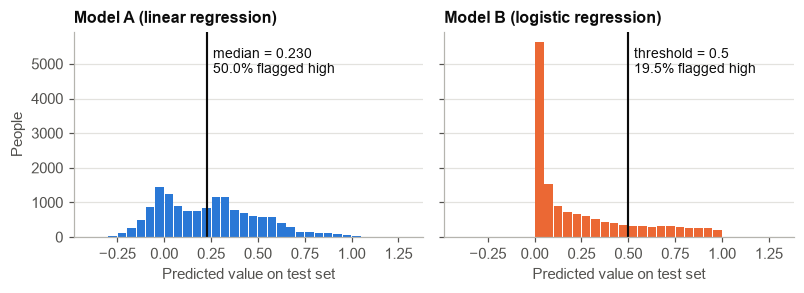

In [10]:
R['spearman_AB'] = test['pA'].corr(test['pB'], method='spearman')
thr_match = np.sort(test['pA'])[-R['n_B_high']]
R['thr_A_matched'] = thr_match
R['mismatch_same_count'] = ((test.pA >= thr_match).astype(int) != test.B_high).mean()
R['mismatch_both_half'] = ((test.pA >= .5).astype(int) != test.B_high).mean()
R['mismatch_both_median'] = (test.A_high != (test.pB >= test.pB.median()).astype(int)).mean()
R['n_mismatch_same_count'] = int(((test.pA >= thr_match).astype(int) != test.B_high).sum())
print(f"rank correlation of A and B scores: {R['spearman_AB']:.4f}")
print(f"A flags as many as B (threshold {thr_match:.4f}): mismatch {R['mismatch_same_count']:.2%}")
print(f"both at 0.5:    {R['mismatch_both_half']:.2%}")
print(f"both at median: {R['mismatch_both_median']:.2%}")

fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.75), sharey=True)
bins = np.arange(-0.4, 1.301, 0.05)
for a, col, c, thr, lab, ttl in [(ax[0], 'pA', BLUE, median_A, f'median = {median_A:.3f}', 'Model A (linear regression)'),
                                 (ax[1], 'pB', ORANGE, 0.5, 'threshold = 0.5', 'Model B (logistic regression)')]:
    a.hist(test[col], bins=bins, color=c, rwidth=0.9)
    a.axvline(thr, color=INK, lw=1.4)
    share = (test[col] >= thr).mean()
    a.text(thr + 0.03, 0.80, f'{lab}\n{share:.1%} flagged high', color=INK, fontsize=9, transform=a.get_xaxis_transform())
    a.set_title(ttl); a.set_xlabel('Predicted value on test set'); a.grid(axis='x', visible=False)
ax[0].set_ylabel('People')
plt.tight_layout(); plt.savefig(FIG / 'fig1_thresholds.png'); plt.show()

## 3. Part 2.1 – Simpson's paradox hunt
* **Split variable:** marital status. Subgroup A = married, Subgroup B = not married.
* **Key predictor:** sex (`male`).
* The same model is fitted to the full cleaned dataset and to each subgroup. Marital status is left out of all three,
  because it is the splitting variable and is constant inside a subgroup.

In [11]:
full = pd.concat([train, test]).sort_index()
GROUPS = {'Full dataset': full, 'A: Married': full[full.married == 1], 'B: Not married': full[full.married == 0]}
simp, R['simpson'] = [], {}
for name, d in GROUPS.items():
    raw_m, raw_f = d[d.male == 1].y, d[d.male == 0].y
    u = sm.Logit(d.y, sm.add_constant(d[['male']].astype(float))).fit(disp=0)
    a = fit_logit(d, drop=('marital',))
    rec = {'n': len(d), 'n_men': len(raw_m), 'n_women': len(raw_f), 'rate_men': raw_m.mean(), 'rate_women': raw_f.mean(),
           'unadj': u.params['male'], 'unadj_lo': u.conf_int().loc['male', 0], 'unadj_hi': u.conf_int().loc['male', 1], 'unadj_p': u.pvalues['male'],
           'adj': a.params['male'], 'adj_lo': a.conf_int().loc['male', 0], 'adj_hi': a.conf_int().loc['male', 1], 'adj_p': a.pvalues['male'],
           'adj_se': a.bse['male'], 'adj_or': np.exp(a.params['male'])}
    for v in ['age', 'education_num', 'hours_per_week', 'race: Black']:
        rec[v] = a.params[v]; rec[v + '_lo'], rec[v + '_hi'] = a.conf_int().loc[v]
    R['simpson'][name] = rec
    simp.append(pd.Series(rec, name=name))
simp = pd.DataFrame(simp).T
simp.to_csv(RES / 'simpson_models.csv')
display(simp.astype(float).round(4))

,Full dataset,A: Married,B: Not married
n,48790.0000,22403.0000,26387.0000
n_men,32614.0000,19898.0000,12716.0000
n_women,16176.0000,2505.0000,13671.0000
rate_men,0.3039,0.4458,0.0819
rate_women,0.1094,0.4475,0.0474
unadj,1.2686,-0.0068,0.5833
unadj_lo,1.2139,-0.0904,0.4821
unadj_hi,1.3233,0.0768,0.6845
unadj_p,0.0000,0.8732,0.0000
adj,1.1325,-0.3196,0.6442


z-test for B minus A: z = 11.29, p = 1.55e-29
                  coef      lo      hi    p
male            0.6835  0.5690  0.7979  0.0
married         3.1607  3.0299  3.2916  0.0
male_x_married -1.1195 -1.2728 -0.9663  0.0

Work 20 hours a week or less:
                size    mean
married sex                 
0       Female  2029  0.0089
        Male    1274  0.0126
1       Female   355  0.3493
        Male     788  0.1815

Clerical jobs:
                size    mean
married sex                 
0       Female  3203  0.0187
        Male     902  0.0510
1       Female   561  0.4439
        Male     940  0.4394
{'share_married_men': np.float64(0.6101), 'share_married_women': np.float64(0.1549), 'rate_married': np.float64(0.446), 'rate_unmarried': np.float64(0.064), 'n_married_men': 19898, 'n_married_women': 2505, 'n_husband': 19703, 'n_wife': 2331, 'men_per_woman_married': 7.9433}


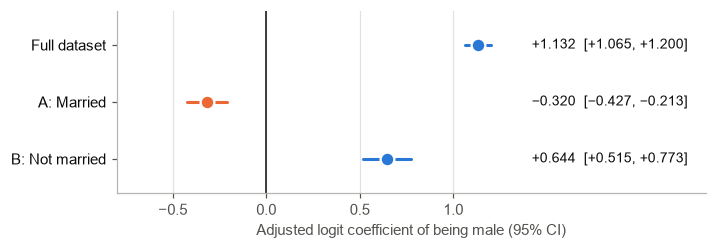

In [12]:
# Is the difference between the two subgroup coefficients statistically real?
sA, sB = R['simpson']['A: Married'], R['simpson']['B: Not married']
z = (sB['adj'] - sA['adj']) / np.hypot(sA['adj_se'], sB['adj_se'])
R['simpson_z'], R['simpson_z_p'] = z, 2 * st.norm.sf(abs(z))
inter = fit_logit(full, drop=('marital',), extra={'married': lambda d: d['married'],
                                                  'male_x_married': lambda d: d['male'] * d['married']})
R['inter'] = {k: {'coef': inter.params[k], 'lo': inter.conf_int().loc[k, 0], 'hi': inter.conf_int().loc[k, 1], 'p': inter.pvalues[k]}
              for k in ['male', 'married', 'male_x_married']}
print(f"z-test for B minus A: z = {z:.2f}, p = {R['simpson_z_p']:.2e}")
print(pd.DataFrame(R['inter']).T.round(4))

# Composition: why does the pooled model see a large positive effect of being male?
comp = {'share_married_men': full[full.male == 1].married.mean(), 'share_married_women': full[full.male == 0].married.mean(),
        'rate_married': full[full.married == 1].y.mean(), 'rate_unmarried': full[full.married == 0].y.mean(),
        'n_married_men': int(((full.married == 1) & (full.male == 1)).sum()), 'n_married_women': int(((full.married == 1) & (full.male == 0)).sum()),
        'n_husband': int((full.relationship == 'Husband').sum()), 'n_wife': int((full.relationship == 'Wife').sum())}
comp['men_per_woman_married'] = comp['n_married_men'] / comp['n_married_women']
# Evidence that the label behaves like a household figure for married people
pt = full[full.hours_per_week <= 20].groupby(['married', 'sex']).y.agg(['size', 'mean'])
cl = full[full.occ == 'Adm-clerical'].groupby(['married', 'sex']).y.agg(['size', 'mean'])
for lab, t in [('pt', pt), ('cl', cl)]:
    for (m, s), r in t.iterrows():
        comp[f"{lab}_{'mar' if m else 'unm'}_{s}"] = r['mean']; comp[f"{lab}_{'mar' if m else 'unm'}_{s}_n"] = int(r['size'])
R['comp'] = comp
print('\nWork 20 hours a week or less:'); print(pt.round(4))
print('\nClerical jobs:'); print(cl.round(4))
print({k: round(v, 4) for k, v in comp.items() if not k.startswith(('pt', 'cl'))})

fig, ax = plt.subplots(figsize=(6.6, 2.35))
names = ['Full dataset', 'A: Married', 'B: Not married'][::-1]
for i, n in enumerate(names):
    r = R['simpson'][n]
    c = ORANGE if r['adj'] < 0 else BLUE
    ax.plot([r['adj_lo'], r['adj_hi']], [i, i], color=c, lw=2, solid_capstyle='round')
    ax.plot(r['adj'], i, 'o', ms=9, color=c, mec='white', mew=1.5)
    ax.text(1.42, i, f"{r['adj']:+.3f}  [{r['adj_lo']:+.3f}, {r['adj_hi']:+.3f}]".replace('-', '−'), va='center', fontsize=9, color=INK)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(range(3)); ax.set_yticklabels(names, color=INK); ax.set_ylim(-.6, 2.6); ax.set_xlim(-.8, 2.35)
ax.set_xticks([-.5, 0, .5, 1]); ax.grid(axis='y', visible=False)
ax.set_xlabel('Adjusted logit coefficient of being male (95% CI)')
plt.tight_layout(); plt.savefig(FIG / 'fig2_simpson.png'); plt.show()

## 4. Part 2.2 – Omitted-variable bias
**Dropped variable:** marital status. It is linked both to the outcome (married 44.6% vs not married 6.4% above \$50K) and to
sex, age and race, so it is a confounder for those coefficients. The full model is Model B; the reduced model is the same
model without the marital dummies. Both are fitted on the training set.

In [13]:
reduced = fit_logit(train, drop=('marital',))
KEYS = ['male', 'race: Black', 'age', 'education_num', 'hours_per_week', 'log_capital_gain', 'occ: Exec-managerial', 'work: Self-emp-inc']
ovb = pd.DataFrame({'full': model_B.params[KEYS], 'full_lo': model_B.conf_int().loc[KEYS, 0], 'full_hi': model_B.conf_int().loc[KEYS, 1],
                    'p_full': model_B.pvalues[KEYS], 'reduced': reduced.params[KEYS],
                    'red_lo': reduced.conf_int().loc[KEYS, 0], 'red_hi': reduced.conf_int().loc[KEYS, 1]})
ovb['pct_change'] = (ovb['reduced'] - ovb['full']) / ovb['full'] * 100
ame_full, ame_red = model_B.get_margeff(at='overall').summary_frame()['dy/dx'], reduced.get_margeff(at='overall').summary_frame()['dy/dx']
ovb['AME_full'], ovb['AME_reduced'] = ame_full[KEYS], ame_red[KEYS]
ovb['AME_pct_change'] = (ovb['AME_reduced'] - ovb['AME_full']) / ovb['AME_full'] * 100
ovb.to_csv(RES / 'omitted_variable.csv')
R['ovb'] = ovb.to_dict('index')
pr = reduced.predict(design(test, drop=('marital',)))
R.update(ovb_auc_red=roc_auc_score(test.y, pr), ovb_acc_red=((pr >= .5) == test.y).mean(), ovb_pr2_red=reduced.prsquared,
         ovb_acc_full=R['acc_B'], or_male_full=np.exp(model_B.params['male']), or_male_red=np.exp(reduced.params['male']))
display(ovb.round(4))
print(f"test AUC  full {R['auc_B']:.4f} -> reduced {R['ovb_auc_red']:.4f};  accuracy {R['acc_B']:.4f} -> {R['ovb_acc_red']:.4f}")
print(f"odds ratio for being male: full {R['or_male_full']:.3f} -> reduced {R['or_male_red']:.3f}")

# Proxy check: if `relationship` had been kept, dropping only marital status would hide the problem.
rel = {f'rel: {l}': (lambda d, l=l: d['relationship'] == l) for l in sorted(df.relationship.unique()) if l != 'Not-in-family'}
with_rel, with_rel_red = fit_logit(train, extra=rel), fit_logit(train, drop=('marital',), extra=rel)
R['rel_male_full'], R['rel_male_red'] = with_rel.params['male'], with_rel_red.params['male']
R['rel_pct'] = (with_rel_red.params['male'] / with_rel.params['male'] - 1) * 100
R['rel_auc_full'] = roc_auc_score(test.y, with_rel.predict(design(test, extra=rel)))
R['rel_auc_red'] = roc_auc_score(test.y, with_rel_red.predict(design(test, drop=('marital',), extra=rel)))
print(f"with `relationship` kept: male {R['rel_male_full']:.3f} -> {R['rel_male_red']:.3f} ({R['rel_pct']:+.1f}%), AUC {R['rel_auc_full']:.4f} -> {R['rel_auc_red']:.4f}")

,full,full_lo,full_hi,p_full,reduced,red_lo,red_hi,pct_change,AME_full,AME_reduced,AME_pct_change
male,0.1131,0.0166,0.2097,0.0217,1.1410,1.0604,1.2215,908.6734,0.0118,0.1397,1080.5550
race: Black,-0.2302,-0.3688,-0.0915,0.0011,-0.4639,-0.5921,-0.3356,101.5443,-0.0241,-0.0568,135.8882
age,0.3837,0.3426,0.4248,0.0000,0.5823,0.5478,0.6169,51.7750,0.0401,0.0713,77.6380
education_num,0.7238,0.6800,0.7676,0.0000,0.6502,0.6097,0.6906,-10.1730,0.0757,0.0796,5.1338
hours_per_week,0.3862,0.3488,0.4236,0.0000,0.4013,0.3671,0.4354,3.9110,0.0404,0.0491,21.6178
log_capital_gain,0.5180,0.4877,0.5483,0.0000,0.5051,0.4773,0.5330,-2.4817,0.0542,0.0619,14.1358
occ: Exec-managerial,0.7162,0.5773,0.8552,0.0000,0.7327,0.6056,0.8599,2.3050,0.0749,0.0897,19.7382
work: Self-emp-inc,0.1767,0.0194,0.3340,0.0277,0.3423,0.1959,0.4888,93.7056,0.0185,0.0419,126.7138


test AUC  full 0.8955 -> reduced 0.8521;  accuracy 0.8436 -> 0.8240
odds ratio for being male: full 1.120 -> reduced 3.130


with `relationship` kept: male 0.739 -> 0.709 (-4.0%), AUC 0.8970 -> 0.8966


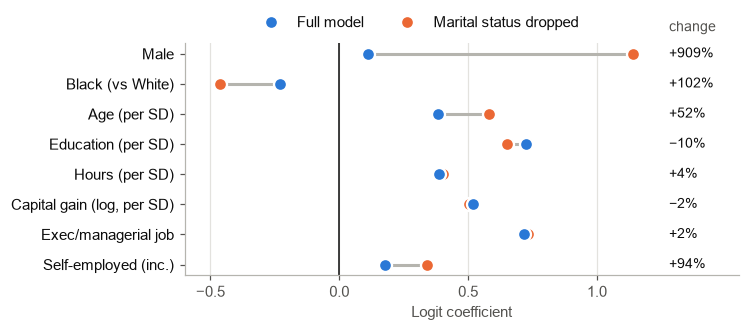

In [14]:
fig, ax = plt.subplots(figsize=(6.9, 3.1))
LABEL = {'male': 'Male', 'race: Black': 'Black (vs White)', 'age': 'Age (per SD)', 'education_num': 'Education (per SD)',
         'hours_per_week': 'Hours (per SD)', 'log_capital_gain': 'Capital gain (log, per SD)',
         'occ: Exec-managerial': 'Exec/managerial job', 'work: Self-emp-inc': 'Self-employed (inc.)'}
for i, k in enumerate(KEYS[::-1]):
    f, r_ = ovb.loc[k, 'full'], ovb.loc[k, 'reduced']
    ax.plot([f, r_], [i, i], color='#b5b4ae', lw=2, zorder=1)
    ax.plot(f, i, 'o', ms=8.5, color=BLUE, mec='white', mew=1.5, zorder=3, label='Full model' if i == 0 else None)
    ax.plot(r_, i, 'o', ms=8.5, color=ORANGE, mec='white', mew=1.5, zorder=2, label='Marital status dropped' if i == 0 else None)
    ax.text(1.28, i, f"{ovb.loc[k, 'pct_change']:+,.0f}%".replace('-', '−'), va='center', fontsize=9, color=INK)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(range(len(KEYS))); ax.set_yticklabels([LABEL[k] for k in KEYS[::-1]], color=INK)
ax.set_xlim(-.6, 1.55); ax.set_xticks([-.5, 0, .5, 1]); ax.grid(axis='y', visible=False)
ax.set_xlabel('Logit coefficient'); ax.text(1.28, len(KEYS) - .35, 'change', fontsize=9, color=MUTED, va='bottom')
ax.legend(loc='lower center', bbox_to_anchor=(.42, 1.0), ncol=2)
plt.tight_layout(); plt.savefig(FIG / 'fig3_omitted.png'); plt.show()

### Pilot test for a hidden confound: is the label itself the problem?
UCI's documentation for the sister dataset *Census-Income (KDD)* says that its goal field "was drawn from the 'total person
income' field rather than the 'adjusted gross income' and may, therefore, behave differently than the orginal ADULT goal field"
(sic). Adjusted gross income on a **joint** tax return belongs to the couple, not the person. If that is what happened
in Adult, the label is a household number for married people and a personal number for everyone else.

Test: refit the sex coefficient on the KDD data (same survey, 1994–95, personal-income label), restricted to people over 16
who worked at least one week. If the sign reversal is a real labour-market fact it should survive; if it is a label artefact it should vanish.

In [15]:
KDD = fetch('census-income-kdd.zip', 'https://archive.ics.uci.edu/static/public/117/census+income+kdd.zip')
with zipfile.ZipFile(KDD) as z_:
    tar = tarfile.open(fileobj=io.BytesIO(z_.read('census.tar.gz')))
use = {0: 'age', 1: 'workclass', 4: 'education', 7: 'marital', 9: 'occupation', 10: 'race', 12: 'sex', 16: 'capital_gain',
       17: 'capital_loss', 19: 'tax_filer', 39: 'weeks', 40: 'year', 41: 'label'}
kdd = pd.concat([pd.read_csv(tar.extractfile(f), header=None, usecols=list(use), skipinitialspace=True)
                 for f in ('census-income.data', 'census-income.test')], ignore_index=True).rename(columns=use)
kdd['y'] = kdd['label'].str.startswith('50000+').astype(int)
R['kdd_n_all'] = len(kdd)
kdd = kdd[(kdd.age > 16) & (kdd.weeks > 0)].copy()
kdd['male'] = (kdd.sex == 'Male').astype(int)
kdd['married'] = kdd.marital.isin(['Married-civilian spouse present', 'Married-A F spouse present']).astype(int)
EDU = {'Children': 0, 'Less than 1st grade': 1, '1st 2nd 3rd or 4th grade': 2, '5th or 6th grade': 3, '7th and 8th grade': 4, '9th grade': 5,
       '10th grade': 6, '11th grade': 7, '12th grade no diploma': 8, 'High school graduate': 9, 'Some college but no degree': 10,
       'Associates degree-occup /vocational': 11, 'Associates degree-academic program': 12, 'Bachelors degree(BA AB BS)': 13,
       'Masters degree(MA MS MEng MEd MSW MBA)': 14, 'Prof school degree (MD DDS DVM LLB JD)': 15, 'Doctorate degree(PhD EdD)': 16}
kdd['edu'] = kdd.education.map(EDU); assert kdd.edu.notna().all()
kdd['occupation'] = kdd.occupation.replace({'Armed Forces': 'Protective services', 'Private household services': 'Other service'})

def kdd_design(d):
    X = pd.DataFrame({'age': d.age, 'edu': d.edu, 'weeks': d.weeks, 'lcg': np.log1p(d.capital_gain), 'lcl': np.log1p(d.capital_loss)}).astype(float)
    X = (X - X.mean()) / X.std(ddof=0)
    X['male'] = d.male.astype(float)
    # occupation and class of worker overlap almost completely here ('Not in universe' in both), so only occupation is used
    for c in ['occupation', 'race']:
        for lev in sorted(kdd[c].unique())[1:]:
            X[f'{c}: {lev}'] = (d[c] == lev).astype(float)
    return sm.add_constant(X)

R['kdd'] = {'n': len(kdd), 'base': kdd.y.mean(), 'n_married_men': int(((kdd.married == 1) & (kdd.male == 1)).sum()),
            'n_married_women': int(((kdd.married == 1) & (kdd.male == 0)).sum())}
R['kdd']['men_per_woman_married'] = R['kdd']['n_married_men'] / R['kdd']['n_married_women']
R['kdd']['share_married_filing_joint'] = kdd.loc[kdd.married == 1, 'tax_filer'].str.startswith('Joint').mean()
out = []
for name, d in {'Full dataset': kdd, 'A: Married': kdd[kdd.married == 1], 'B: Not married': kdd[kdd.married == 0]}.items():
    u = sm.Logit(d.y, sm.add_constant(d[['male']].astype(float))).fit(disp=0)
    a = sm.Logit(d.y, kdd_design(d)).fit(disp=0, maxiter=300)
    assert a.mle_retvals['converged']
    R['kdd'][name] = {'n': len(d), 'rate_men': d[d.male == 1].y.mean(), 'rate_women': d[d.male == 0].y.mean(), 'unadj': u.params['male'],
                      'unadj_lo': u.conf_int().loc['male', 0], 'unadj_hi': u.conf_int().loc['male', 1], 'adj': a.params['male'],
                      'adj_lo': a.conf_int().loc['male', 0], 'adj_hi': a.conf_int().loc['male', 1], 'adj_p': a.pvalues['male']}
    out.append(pd.Series(R['kdd'][name], name=name))
display(pd.DataFrame(out))
print({k: v for k, v in R['kdd'].items() if not isinstance(v, dict)})

,n,rate_men,rate_women,unadj,unadj_lo,unadj_hi,adj,adj_lo,adj_hi,adj_p
Full dataset,152959.0,0.174612,0.050066,1.389765,1.351768,1.427762,1.238862,1.194771,1.282953,0.000000e+00
A: Married,91779.0,0.232186,0.052747,1.692058,1.644188,1.739928,1.446174,1.391415,1.500932,0.000000e+00
B: Not married,61180.0,0.076768,0.046551,0.532448,0.464804,0.600091,0.697531,0.616114,0.778947,2.801529e-63


{'n': 152959, 'base': np.float64(0.11546231343039638), 'n_married_men': 50563, 'n_married_women': 41216, 'men_per_woman_married': 1.2267808618012421, 'share_married_filing_joint': np.float64(0.9942470499787533)}


## 5. Part 2.3 – Adversarial subset
Confident errors on the test set: `P ≥ 0.75` but `y = 0` (false positive) or `P ≤ 0.25` but `y = 1` (false negative).

In [16]:
test['FP_conf'] = (test.pB >= .75) & (test.y == 0)
test['FN_conf'] = (test.pB <= .25) & (test.y == 1)
test['conf_wrong'] = test.FP_conf | test.FN_conf
conf = (test.pB >= .75) | (test.pB <= .25)
adv = test[test.conf_wrong].sort_index().sample(n=min(50, int(test.conf_wrong.sum())), random_state=SEED)

lo, hi = test[test.pB <= .25], test[test.pB >= .75]
R['adv'] = dict(n=int(test.conf_wrong.sum()), pct=test.conf_wrong.mean(), n_fp=int(test.FP_conf.sum()), n_fn=int(test.FN_conf.sum()),
                n_conf=int(conf.sum()), pct_of_conf=test.conf_wrong.sum() / conf.sum(), n_lo=len(lo), n_hi=len(hi),
                exp_fn=lo.pB.sum(), exp_fp=(1 - hi.pB).sum(), s_n=len(adv), s_fp=int(adv.FP_conf.sum()), s_fn=int(adv.FN_conf.sum()))
R['adv']['fp_excess'] = R['adv']['n_fp'] / R['adv']['exp_fp'] - 1
R['adv']['fn_excess'] = R['adv']['n_fn'] / R['adv']['exp_fn'] - 1

def profile(d):
    nocap = (d.capital_gain == 0) & (d.capital_loss == 0); deg = d.education_num >= 13; mar = d.married == 1
    favoured = mar & deg
    return pd.Series({'n': len(d), 'mean age': d.age.mean(), 'age 17-29': (d.age < 30).mean(), 'age 30-44': d.age.between(30, 44).mean(), 'age 45-59': d.age.between(45, 59).mean(),
        'age 60+': (d.age >= 60).mean(), 'age 30+': (d.age >= 30).mean(), 'male': d.male.mean(), 'married': mar.mean(),
        'never married': (d.marital == 'Never-married').mean(), 'white': (d.race == 'White').mean(), 'black': (d.race == 'Black').mean(),
        'US-born': (d.origin == 'US').mean(), "bachelor's or higher": deg.mean(), 'mean education level (1-16)': d.education_num.mean(),
        'mean hours/week': d.hours_per_week.mean(), 'works 40+ hours': (d.hours_per_week >= 40).mean(),
        'exec or professional job': d.occ.isin(['Exec-managerial', 'Prof-specialty']).mean(), 'no capital gain or loss': nocap.mean(),
        'capital gain 1-6,999': d.capital_gain.between(1, 6999).mean(), 'capital gain 7,000+': (d.capital_gain >= 7000).mean(),
        'outcome contradicts marriage+degree cue': ((favoured & (d.y == 0)) | (~favoured & (d.y == 1))).mean(),
        'earns >50K': d.y.mean()})
prof = pd.DataFrame({'Adversarial 50': profile(adv), 'All confident errors': profile(test[test.conf_wrong]), 'Full test set': profile(test),
                     '50: false neg.': profile(adv[adv.FN_conf]), '50: false pos.': profile(adv[adv.FP_conf]),
                     'All false neg.': profile(test[test.FN_conf]), 'All false pos.': profile(test[test.FP_conf])})
prof.to_csv(RES / 'adversarial_profile.csv'); R['adv_profile'] = prof.to_dict()
# the rows that do NOT show the common characteristic: what do they have instead?
fav = (adv.married == 1) & (adv.education_num >= 13)
contra = (fav & (adv.y == 0)) | (~fav & (adv.y == 1))
exc = adv[~contra]
R['adv'].update(n_contra=int(contra.sum()), n_exc=len(exc), exc_fp=int(exc.FP_conf.sum()),
                exc_capital=int(((exc.capital_gain.between(1, 6999)) | (exc.capital_loss > 0)).sum()),
                exc_gain=int(exc.capital_gain.between(1, 6999).sum()), exc_loss=int((exc.capital_loss > 0).sum()),
                fn_married=int(adv[adv.FN_conf].married.sum()), fn_unmarried=int((adv[adv.FN_conf].married == 0).sum()),
                fp_smallgain=int(adv[adv.FP_conf].capital_gain.between(1, 6999).sum()), fp_married=int(adv[adv.FP_conf].married.sum()))
un = test[test.married == 0]
R['unm_p_le25'], R['unm_rich_le25'] = (un.pB <= .25).mean(), (un[un.y == 1].pB <= .25).mean()
R['unm_recall50'] = (un[un.y == 1].pB >= .5).mean()
R['edu_sd_to_offset_marriage'] = model_B.params['marital: Married'] / model_B.params['education_num']
R['edu_levels_to_offset_marriage'] = R['edu_sd_to_offset_marriage'] * SD['education_num']
print('common characteristic:', R['adv']['n_contra'], 'of', len(adv), '| exceptions:', R['adv']['n_exc'], '| exceptions with small capital gain/loss:', R['adv']['exc_capital'])
print('unmarried with P<=0.25:', round(R['unm_p_le25'], 4), '| unmarried >50K earners with P<=0.25:', round(R['unm_rich_le25'], 4),
      '| education SDs needed to offset marriage:', round(R['edu_sd_to_offset_marriage'], 2), '=', round(R['edu_levels_to_offset_marriage'], 2), 'levels')
show = ['age', 'sex', 'marital', 'race', 'occ', 'education_num', 'hours_per_week', 'capital_gain', 'capital_loss', 'pB', 'y']
adv[show].sort_values('pB').to_csv(RES / 'adversarial_50.csv', index_label='row_id')
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in R['adv'].items()})
display(prof.round(3)); display(adv[show].sort_values('pB'))

common characteristic: 44 of 50 | exceptions: 6 | exceptions with small capital gain/loss: 6
unmarried with P<=0.25: 0.945 | unmarried >50K earners with P<=0.25: 0.5981 | education SDs needed to offset marriage: 3.63 = 9.33 levels
{'n': 830, 'pct': np.float64(0.0567), 'n_fp': 209, 'n_fn': 621, 'n_conf': 10745, 'pct_of_conf': np.float64(0.0772), 'n_lo': 9470, 'n_hi': 1275, 'exp_fn': np.float64(598.9521), 'exp_fp': np.float64(170.1571), 's_n': 50, 's_fp': 12, 's_fn': 38, 'fp_excess': np.float64(0.2283), 'fn_excess': np.float64(0.0368), 'n_contra': 44, 'n_exc': 6, 'exc_fp': 6, 'exc_capital': 6, 'exc_gain': 5, 'exc_loss': 1, 'fn_married': 21, 'fn_unmarried': 17, 'fp_smallgain': 6, 'fp_married': 11}


,Adversarial 50,All confident errors,Full test set,50: false neg.,50: false pos.,All false neg.,All false pos.
n,50.00,830.000,14637.000,38.000,12.000,621.000,209.000
mean age,46.44,43.790,38.667,43.395,56.083,41.580,50.359
age 17-29,0.06,0.110,0.295,0.079,0.000,0.129,0.053
age 30-44,0.40,0.451,0.384,0.474,0.167,0.501,0.301
age 45-59,0.40,0.329,0.236,0.368,0.500,0.306,0.397
age 60+,0.14,0.111,0.086,0.079,0.333,0.064,0.249
age 30+,0.94,0.890,0.705,0.921,1.000,0.871,0.947
male,0.66,0.770,0.670,0.605,0.833,0.721,0.914
married,0.64,0.617,0.460,0.553,0.917,0.494,0.981
never married,0.20,0.198,0.330,0.263,0.000,0.264,0.000


,age,sex,marital,race,occ,education_num,hours_per_week,capital_gain,capital_loss,pB,y
1327,52,Female,Widowed,Asian-Pac-Islander,Other-service,9,40,0,0,0.013486,1
12526,39,Female,Never-married,White,Adm-clerical,9,40,0,0,0.021509,1
37577,31,Female,Never-married,White,Exec-managerial,10,40,0,0,0.045479,1
36101,56,Male,Married,White,Machine-op-inspct,3,40,0,0,0.046775,1
25069,29,Male,Married,White,Craft-repair,6,35,0,0,0.055383,1
44948,51,Female,Married,White,Unknown,9,3,0,0,0.063900,1
3992,52,Male,Divorced/Separated,White,Craft-repair,9,55,0,0,0.083626,1
35447,40,Male,Never-married,Black,Machine-op-inspct,9,40,14344,0,0.085598,1
30057,54,Female,Never-married,White,Exec-managerial,10,45,0,0,0.096309,1
11948,43,Female,Married,White,Adm-clerical,9,20,0,0,0.098557,1


### Why does the model fail confidently?
Two different things are mixed together, so they are separated:
* **Expected errors.** A well-calibrated model that says P = 0.10 is wrong 10% of the time. The expected number of confident
  errors is the sum of `p` (low side) and `1 − p` (high side).
* **Systematic errors.** Groups where the average prediction is far from the observed rate.

In [17]:
def calib(by, label):
    t = test.groupby(by, observed=True).agg(n=('y', 'size'), observed=('y', 'mean'), predicted=('pB', 'mean'),
                                           conf_FP=('FP_conf', 'sum'), conf_FN=('FN_conf', 'sum'))
    t['gap'] = t.predicted - t.observed; t.index.name = label
    return t
cg = calib(pd.cut(test.capital_gain, [-1, 0, 3000, 5000, 5060, 6999, 99998, 100000],
                  labels=['0', '1-3,000', '3,001-5,000', '5,001-5,060', '5,061-6,999', '7,000-99,998', '99,999']), 'capital_gain')
ag = calib(pd.cut(test.age, [16, 25, 35, 45, 55, 65, 100], labels=['17-25', '26-35', '36-45', '46-55', '56-65', '66+']), 'age')
ms = calib([test.marital, test.sex], 'group')
R['cal_cg'] = cg.reset_index().astype({'capital_gain': str}).set_index('capital_gain').to_dict('index')
R['cal_age'] = ag.reset_index().astype({'age': str}).set_index('age').to_dict('index')
R['cal_ms'] = {f'{a}|{b}': r.to_dict() for (a, b), r in ms.iterrows()}
low = test.capital_gain.between(1, 5060)
R['cg_small'] = dict(n=int(low.sum()), obs=test[low].y.mean(), pred=test[low].pB.mean(), fp=int(test[low].FP_conf.sum()), npos=int((test[low].pB >= .75).sum()))
big = test.capital_gain >= 7000
R['cg_big'] = dict(n=int(big.sum()), obs=test[big].y.mean(), pred=test[big].pB.mean(), fn=int(test[big].FN_conf.sum()))
vivid = adv[(adv.FN_conf) & (adv.capital_gain == 99999)]
R['vivid'] = vivid[show].reset_index().to_dict('records')
# log-odds arithmetic for the largest possible capital gain against being married
R['lo_cg_max'] = (np.log1p(99999) - MU['log_capital_gain']) / SD['log_capital_gain'] * model_B.params['log_capital_gain']
R['lo_cg_zero'] = (0 - MU['log_capital_gain']) / SD['log_capital_gain'] * model_B.params['log_capital_gain']
R['lo_cg_swing'] = R['lo_cg_max'] - R['lo_cg_zero']
R['lo_cg_5013'] = (np.log1p(5013) - np.log1p(0)) / SD['log_capital_gain'] * model_B.params['log_capital_gain']
for t in (cg, ag, ms): display(t.round(3))
print('small gains 1-5,060:', R['cg_small']); print('large gains 7,000+:', R['cg_big'])
print('log-odds swing of capital gain 0 -> 99,999:', round(R['lo_cg_swing'], 3), ' | 0 -> 5,013:', round(R['lo_cg_5013'], 3), '| married:', round(model_B.params['marital: Married'], 3))
print('99,999-gain cases in the 50:', R['vivid'])

,n,observed,predicted,conf_FP,conf_FN,gap
capital_gain,,,,,,
0,13430,0.206,0.206,129,597,-0.000
"1-3,000",206,0.000,0.289,19,0,0.289
"3,001-5,000",290,0.331,0.544,40,2,0.213
"5,001-5,060",31,0.000,0.713,18,0,0.713
"5,061-6,999",89,0.663,0.651,2,0,-0.012
"7,000-99,998",526,0.983,0.775,1,20,-0.208
"99,999",65,1.000,0.889,0,2,-0.111


,n,observed,predicted,conf_FP,conf_FN,gap
age,,,,,,
17-25,2888,0.018,0.039,1,22,0.021
26-35,3776,0.191,0.195,30,198,0.004
36-45,3596,0.347,0.316,48,185,-0.030
46-55,2509,0.387,0.363,58,139,-0.024
56-65,1327,0.307,0.350,39,61,0.042
66+,541,0.192,0.298,33,16,0.106


n  observed  predicted  conf_FP  conf_FN    gap
marital            sex                                                       
Divorced/Separated Female  1568     0.066      0.085        2       63  0.019
                   Male    1067     0.132      0.112        2       67 -0.020
Married            Female   758     0.429      0.373       16       48 -0.055
                   Male    5974     0.444      0.458      189      259  0.014
Never-married      Female  2153     0.039      0.045        0       51  0.005
                   Male    2684     0.059      0.046        0      113 -0.013
Widowed            Female   350     0.051      0.056        0       11  0.005
                   Male      83     0.229      0.130        0        9 -0.099

small gains 1-5,060: {'n': 527, 'obs': np.float64(0.18216318785578747), 'pred': np.float64(0.4542915007225363), 'fp': 77, 'npos': 124}
large gains 7,000+: {'n': 591, 'obs': np.float64(0.9847715736040609), 'pred': np.float64(0.7872888263041201), 'fn': 22}
log-odds swing of capital gain 0 -> 99,999: 2.43  | 0 -> 5,013: 1.799 | married: 2.624
99,999-gain cases in the 50: [{'index': 1826, 'age': 22, 'sex': 'Female', 'marital': 'Never-married', 'race': 'White', 'occ': 'Prof-specialty', 'education_num': 9, 'hours_per_week': 40, 'capital_gain': 99999, 'capital_loss': 0, 'pB': 0.11323743169682128, 'y': 1}]


,conf_FP,conf_FN,conf_wrong,of the 50 still wrong,AUC,accuracy,log_loss
Model B (baseline),209.0,621.0,830.0,50.0,0.8955,0.8436,0.3366
+ age^2,213.0,600.0,813.0,43.0,0.8993,0.8479,0.3301
+ sex x married,213.0,620.0,833.0,47.0,0.8966,0.8453,0.3351
+ capital-gain steps,148.0,621.0,769.0,37.0,0.9044,0.8542,0.3179
+ hours^2,209.0,614.0,823.0,49.0,0.8961,0.8442,0.3353
+ all four,154.0,601.0,755.0,35.0,0.9097,0.8583,0.3095
Gradient boosting,90.0,487.0,577.0,28.0,0.9276,0.8744,0.2775


                    coef             p
age2           -0.407302  1.801082e-75
male_x_married -1.345757  2.462091e-39
cg_1_5060      -2.456976  2.123468e-33
cg_7000plus     3.558452  4.492299e-27
hours2         -0.076893  7.398073e-12


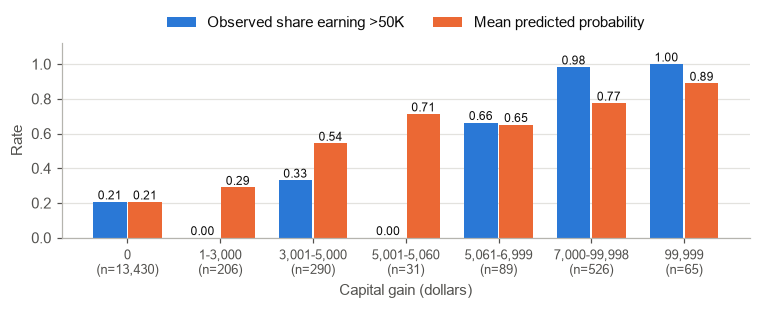

In [18]:
# Repair experiment: add the suspected missing terms and count the confident errors again.
TERMS = {'age^2': {'age2': lambda d: ((d.age - MU['age']) / SD['age']) ** 2},
         'sex x married': {'male_x_married': lambda d: d.male * d.married},
         'capital-gain steps': {'cg_1_5060': lambda d: d.capital_gain.between(1, 5060), 'cg_7000plus': lambda d: d.capital_gain >= 7000},
         'hours^2': {'hours2': lambda d: ((d.hours_per_week.clip(HOURS_LO, HOURS_HI) - MU['hours_per_week']) / SD['hours_per_week']) ** 2}}
TERMS['all four'] = {k: v for t in list(TERMS.values()) for k, v in t.items()}

def score(name, p):
    p = pd.Series(np.asarray(p), index=test.index); fp, fn = (p >= .75) & (test.y == 0), (p <= .25) & (test.y == 1)
    return pd.Series({'conf_FP': fp.sum(), 'conf_FN': fn.sum(), 'conf_wrong': (fp | fn).sum(), 'of the 50 still wrong': (fp | fn)[adv.index].sum(),
                      'AUC': roc_auc_score(test.y, p), 'accuracy': ((p >= .5) == test.y).mean(), 'log_loss': log_loss(test.y, p)}, name=name)
rows, R['repair_coef'] = [score('Model B (baseline)', test.pB)], {}
for name, ex in TERMS.items():
    m = fit_logit(train, extra=ex); rows.append(score('+ ' + name, m.predict(design(test, extra=ex))))
    if name == 'all four':
        R['repair_coef'] = {k: {'coef': m.params[k], 'p': m.pvalues[k]} for k in ex}
gb = HistGradientBoostingClassifier(random_state=SEED).fit(design(train), train.y)
rows.append(score('Gradient boosting', gb.predict_proba(design(test))[:, 1]))
repair = pd.DataFrame(rows); repair.to_csv(RES / 'repair_experiment.csv'); R['repair'] = repair.to_dict('index')
display(repair.round(4)); print(pd.DataFrame(R['repair_coef']).T)

fig, ax = plt.subplots(figsize=(7.0, 2.9))
x = np.arange(len(cg)); w = .36
ax.bar(x - w/2 - .01, cg.observed, w, color=BLUE, label='Observed share earning >50K')
ax.bar(x + w/2 + .01, cg.predicted, w, color=ORANGE, label='Mean predicted probability')
for i in x:
    ax.text(i - w/2 - .01, cg.observed.iloc[i] + .015, f'{cg.observed.iloc[i]:.2f}', ha='center', fontsize=8, color=INK)
    ax.text(i + w/2 + .01, cg.predicted.iloc[i] + .015, f'{cg.predicted.iloc[i]:.2f}', ha='center', fontsize=8, color=INK)
ax.set_xticks(x); ax.set_xticklabels([f'{l}\n(n={n:,})' for l, n in zip(cg.index, cg.n)], fontsize=8.2)
ax.set_xlabel('Capital gain (dollars)'); ax.set_ylabel('Rate'); ax.set_ylim(0, 1.12); ax.grid(axis='x', visible=False)
ax.legend(loc='lower center', bbox_to_anchor=(.5, 1.0), ncol=2)
plt.tight_layout(); plt.savefig(FIG / 'fig4_capital_gain.png'); plt.show()

## 6. Part 2.4 – Fairness trade-off
Sensitive variable: **sex**. Group A = women, Group B = men. All ratios are women ÷ men, so a value below 1 means women are
selected (or correctly/incorrectly flagged) less often. Predictions are Model B on the test set.

In [19]:
W, M = test[test.sex == 'Female'], test[test.sex == 'Male']
def rates(d, t):
    h = d.pB >= t
    return dict(sel=h.mean(), tpr=h[d.y == 1].mean(), fpr=h[d.y == 0].mean(), ppv=d.y[h].mean() if h.any() else np.nan,
                acc=(h == d.y).mean(), n_sel=int(h.sum()), tp=int((h & (d.y == 1)).sum()), fp=int((h & (d.y == 0)).sum()))
THRESHOLDS = [round(.05 + .1 * i, 2) for i in range(10)]
rows = []
for t in THRESHOLDS:
    a, b = rates(W, t), rates(M, t)
    tpr_r, fpr_r = a['tpr'] / b['tpr'], a['fpr'] / b['fpr']
    rows.append({'t': t, 'DP': a['sel'] / b['sel'], 'TPR ratio': tpr_r, 'FPR ratio': fpr_r, 'EO': min(tpr_r, fpr_r), 'PP': a['ppv'] / b['ppv'],
                 'accuracy': ((test.pB >= t) == test.y).mean(),
                 **{f'W_{k}': v for k, v in a.items()}, **{f'M_{k}': v for k, v in b.items()}})
sweep = pd.DataFrame(rows).set_index('t'); sweep.to_csv(RES / 'fairness_sweep.csv')
R['sweep'] = {f'{t:.2f}': r.to_dict() for t, r in sweep.iterrows()}
R.update(n_women=len(W), n_men=len(M), base_women=W.y.mean(), base_men=M.y.mean(), pos_women=int(W.y.sum()), pos_men=int(M.y.sum()))
print(f"women n={len(W):,} base rate {W.y.mean():.4f};  men n={len(M):,} base rate {M.y.mean():.4f}")
display(sweep[['DP', 'TPR ratio', 'FPR ratio', 'EO', 'PP', 'accuracy']].round(3))
display(sweep[['W_sel', 'M_sel', 'W_tpr', 'M_tpr', 'W_fpr', 'M_fpr', 'W_ppv', 'M_ppv', 'W_fp', 'M_fp']].round(3))
print('thresholds where all three metrics lie within 0.8-1.25:', [t for t in sweep.index if all(.8 <= sweep.loc[t, c] <= 1.25 for c in ['DP', 'EO', 'PP'])])

women n=4,829 base rate 0.1100;  men n=9,808 base rate 0.3031


,DP,TPR ratio,FPR ratio,EO,PP,accuracy
t,,,,,,
0.05,0.587,0.966,0.594,0.594,0.597,0.615
0.15,0.370,0.875,0.330,0.330,0.859,0.749
0.25,0.292,0.794,0.233,0.233,0.985,0.802
0.35,0.251,0.712,0.187,0.187,1.029,0.834
0.45,0.240,0.697,0.166,0.166,1.053,0.844
0.55,0.215,0.626,0.143,0.143,1.056,0.842
0.65,0.176,0.501,0.121,0.121,1.033,0.835
0.75,0.169,0.454,0.150,0.150,0.974,0.819
0.85,0.151,0.375,0.212,0.212,0.901,0.798


,W_sel,M_sel,W_tpr,M_tpr,W_fpr,M_fpr,W_ppv,M_ppv,W_fp,M_fp
t,,,,,,,,,,
0.05,0.418,0.712,0.951,0.984,0.352,0.593,0.250,0.419,1514,4054
0.15,0.209,0.566,0.814,0.930,0.134,0.407,0.428,0.498,578,2785
0.25,0.135,0.461,0.674,0.849,0.068,0.291,0.551,0.559,292,1992
0.35,0.092,0.366,0.542,0.762,0.036,0.194,0.649,0.630,156,1329
0.45,0.070,0.292,0.461,0.662,0.022,0.132,0.723,0.686,94,899
0.55,0.050,0.233,0.352,0.562,0.013,0.090,0.773,0.732,55,613
0.65,0.031,0.179,0.232,0.462,0.007,0.056,0.809,0.783,29,380
0.75,0.020,0.120,0.151,0.332,0.004,0.028,0.816,0.838,18,191
0.85,0.010,0.069,0.075,0.201,0.002,0.011,0.800,0.888,10,75


thresholds where all three metrics lie within 0.8-1.25: []


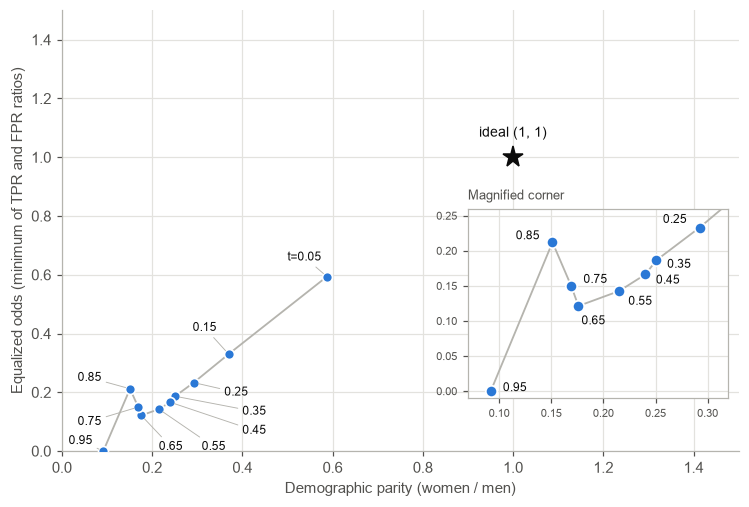

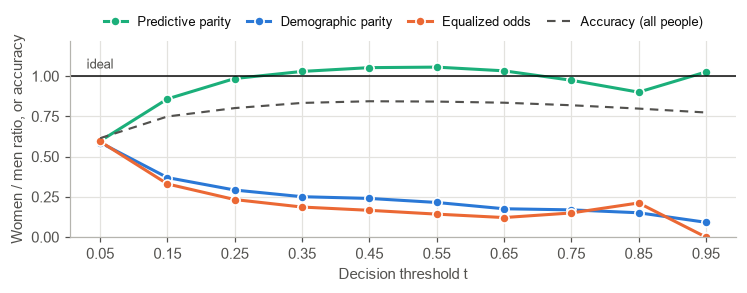

In [20]:
# Trade-off chart on the required 0-1.5 axes, every point labelled; the inset magnifies the crowded corner.
fig, ax = plt.subplots(figsize=(6.9, 4.7))
ax.plot(sweep.DP, sweep.EO, color='#b5b4ae', lw=1.2, zorder=1)
ax.plot(sweep.DP, sweep.EO, 'o', ms=6.5, color=BLUE, mec='white', mew=1.1, zorder=3)
where = {.05: (.50, .66), .15: (.29, .42), .25: (.36, .20), .35: (.40, .135), .45: (.40, .07), .55: (.31, .015), .65: (.215, .015),
         .75: (.035, .10), .85: (.035, .25), .95: (.015, .035)}
for t, (lx, ly) in where.items():
    ax.annotate(f't={t:.2f}' if t == .05 else f'{t:.2f}', (sweep.DP[t], sweep.EO[t]), xytext=(lx, ly), fontsize=7.6, color=INK, va='center',
                arrowprops=dict(arrowstyle='-', color='#b5b4ae', lw=.6, shrinkA=1, shrinkB=3), zorder=4)
ax.plot(1, 1, marker='*', ms=14, color=INK, ls='none'); ax.text(1.0, 1.07, 'ideal (1, 1)', ha='center', fontsize=9)
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.set_xlabel('Demographic parity (women / men)'); ax.set_ylabel('Equalized odds (minimum of TPR and FPR ratios)')
box = (.07, -.01, .25, .27)                                   # x0, y0, width, height of the magnified corner
ins = ax.inset_axes([.60, .12, .385, .43]); ins.set_facecolor('white')
ins.plot(sweep.DP, sweep.EO, color='#b5b4ae', lw=1.2, zorder=1); ins.plot(sweep.DP, sweep.EO, 'o', ms=7.5, color=BLUE, mec='white', mew=1.2, zorder=3)
ins.set_xlim(box[0], box[0] + box[2]); ins.set_ylim(box[1], box[1] + box[3]); ins.tick_params(labelsize=7)
off = {.25: (-24, 3), .35: (7, -5), .45: (7, -6), .55: (6, -9), .65: (2, -12), .75: (8, 2), .85: (-24, 2), .95: (8, 0)}
for t, o in off.items(): ins.annotate(f'{t:.2f}', (sweep.DP[t], sweep.EO[t]), xytext=o, textcoords='offset points', fontsize=8)
ins.set_title('Magnified corner', fontsize=8.5, color=MUTED, fontweight='normal')
for sp_ in ('top', 'right'): ins.spines[sp_].set_visible(True)
plt.tight_layout(); plt.savefig(FIG / 'fig5_tradeoff.png'); plt.show()

fig, a = plt.subplots(figsize=(6.9, 2.75))
for c, col, lab in [('PP', AQUA, 'Predictive parity'), ('DP', BLUE, 'Demographic parity'), ('EO', ORANGE, 'Equalized odds')]:
    a.plot(sweep.index, sweep[c], '-o', color=col, lw=2, ms=6, mec='white', mew=1.1, label=lab)
a.axhline(1, color=INK, lw=1); a.text(.05, 1.03, 'ideal', fontsize=8.5, color=MUTED, ha='center', va='bottom')
a.plot(sweep.index, sweep.accuracy, color=MUTED, lw=1.4, ls=(0, (4, 3)), label='Accuracy (all people)')
a.set_xticks(THRESHOLDS); a.set_ylim(0, 1.22); a.set_xlabel('Decision threshold t'); a.set_ylabel('Women / men ratio, or accuracy')
a.legend(loc='lower center', bbox_to_anchor=(.5, 1.0), ncol=4, fontsize=8.5, columnspacing=1.2, handlelength=1.8)
plt.tight_layout(); plt.savefig(FIG / 'fig6_metrics.png'); plt.show()

### Quantifying the trade-off
`cost = W / Z`, where Z is the percentage gain in the metric being improved and W the percentage loss in the other.
Because DP and EO mostly rise together when the threshold falls, the script first checks **every** pair of thresholds to see where a
genuine DP-versus-EO conflict exists.

In [21]:
def trade(t0, t1, gain='DP', loss='EO'):
    g0, g1, l0, l1 = sweep.loc[t0, gain], sweep.loc[t1, gain], sweep.loc[t0, loss], sweep.loc[t1, loss]
    Z, Wl = (g1 / g0 - 1) * 100, (1 - l1 / l0) * 100
    return dict(t0=t0, t1=t1, g0=g0, g1=g1, Z=Z, l0=l0, l1=l1, W=Wl, cost=Wl / Z, acc0=sweep.accuracy[t0], acc1=sweep.accuracy[t1])
pairs = [(a, b) for a in THRESHOLDS for b in THRESHOLDS if sweep.DP[b] > sweep.DP[a] and sweep.EO[b] < sweep.EO[a]]
R['n_conflict_pairs'], R['n_pairs'] = len(pairs), len(THRESHOLDS) * (len(THRESHOLDS) - 1) // 2
R['conflict_pairs'] = [list(p) for p in pairs]
print(f"{len(pairs)} of {R['n_pairs']} threshold pairs show DP improving while EO falls:", pairs)
R['trade_main'] = trade(.85, .65)                              # DP up, EO down
R['trade_comove'] = trade(.45, .05)                            # DP up, EO up as well
R['trade_pp'] = trade(.25, .05, 'DP', 'PP')                    # DP up, PP down
R['trade_pp_step'] = trade(.25, .15, 'DP', 'PP')
R['trade_eo_pp'] = trade(.25, .05, 'EO', 'PP')
for k in ['trade_main', 'trade_comove', 'trade_pp', 'trade_pp_step', 'trade_eo_pp']:
    print(k, {a: round(b, 4) for a, b in R[k].items()})

# Is t = 0.25 closer to 1 than every higher threshold on all three fairness metrics?
R['t25_beats_all_higher'] = bool(all(abs(sweep.loc[.25, c] - 1) < abs(sweep.loc[t, c] - 1) for t in THRESHOLDS if t > .25 for c in ['DP', 'EO', 'PP']))
R['best_acc_t'], R['best_acc'] = float(sweep.accuracy.idxmax()), sweep.accuracy.max()
R['best_PP_t'] = float((sweep.PP - 1).abs().idxmin())
print('t=0.25 closer to 1 than every higher threshold on DP, EO and PP:', R['t25_beats_all_higher'], '| best PP at t =', R['best_PP_t'], '| best accuracy', round(R['best_acc'], 4), 'at', R['best_acc_t'])

# How noisy is EO at high thresholds? (few women are flagged there)
rng = np.random.default_rng(SEED); boot = {t: [] for t in (.25, .65, .85)}
for _ in range(2000):
    a, b = W.iloc[rng.integers(0, len(W), len(W))], M.iloc[rng.integers(0, len(M), len(M))]
    for t in boot:
        x, z_ = rates(a, t), rates(b, t); boot[t].append(min(x['tpr'] / z_['tpr'], x['fpr'] / z_['fpr']))
R['boot_EO'] = {f'{t:.2f}': list(np.percentile(v, [2.5, 97.5])) for t, v in boot.items()}
R['boot_prob_85_gt_65'] = float(np.mean(np.array(boot[.85]) > np.array(boot[.65])))
print('bootstrap 95% CI for EO:', {k: [round(x, 3) for x in v] for k, v in R['boot_EO'].items()}, '| P(EO.85 > EO.65) =', R['boot_prob_85_gt_65'])

7 of 45 threshold pairs show DP improving while EO falls: [(0.75, 0.55), (0.75, 0.65), (0.85, 0.35), (0.85, 0.45), (0.85, 0.55), (0.85, 0.65), (0.85, 0.75)]
trade_main {'t0': 0.85, 't1': 0.65, 'g0': np.float64(0.1511), 'g1': np.float64(0.176), 'Z': np.float64(16.4698), 'l0': np.float64(0.212), 'l1': np.float64(0.1214), 'W': np.float64(42.7632), 'cost': np.float64(2.5965), 'acc0': np.float64(0.7983), 'acc1': np.float64(0.8349)}
trade_comove {'t0': 0.45, 't1': 0.05, 'g0': np.float64(0.2402), 'g1': np.float64(0.5875), 'Z': np.float64(144.6295), 'l0': np.float64(0.1663), 'l1': np.float64(0.5939), 'W': np.float64(-257.1692), 'cost': np.float64(-1.7781), 'acc0': np.float64(0.844), 'acc1': np.float64(0.6146)}
trade_pp {'t0': 0.25, 't1': 0.05, 'g0': np.float64(0.2923), 'g1': np.float64(0.5875), 'Z': np.float64(101.01), 'l0': np.float64(0.9853), 'l1': np.float64(0.5967), 'W': np.float64(39.4411), 'cost': np.float64(0.3905), 'acc0': np.float64(0.8015), 'acc1': np.float64(0.6146)}
trade_pp_step {

bootstrap 95% CI for EO: {'0.25': [np.float64(0.207), np.float64(0.261)], '0.65': [np.float64(0.077), np.float64(0.17)], '0.85': [np.float64(0.09), np.float64(0.349)]} | P(EO.85 > EO.65) = 0.9405


### What if women and men could have different thresholds?
Men are held at the recommended t = 0.25 and the women's threshold is lowered until (i) DP is closest to 1 and (ii) the worse of the two
equalized-odds ratios is closest to 1. This is the real DP-versus-EO conflict, which a single shared threshold cannot show.

In [22]:
b = rates(M, .25); rows = []
for tw in np.round(np.arange(.01, .2501, .005), 3):
    a = rates(W, tw); tr_, fr_ = a['tpr'] / b['tpr'], a['fpr'] / b['fpr']
    rows.append({'t_women': tw, 'DP': a['sel'] / b['sel'], 'TPR ratio': tr_, 'FPR ratio': fr_, 'PP': a['ppv'] / b['ppv'], 'ppv_women': a['ppv'],
                 'worst_EO_dev': max(abs(np.log(tr_)), abs(np.log(fr_))), 'sel_women': a['sel'], 'fpr_women': a['fpr'], 'tpr_women': a['tpr']})
grp = pd.DataFrame(rows).set_index('t_women'); grp.to_csv(RES / 'group_thresholds.csv')
tDP, tEO = (grp.DP - 1).abs().idxmin(), grp.worst_EO_dev.idxmin()
R['grp_DP'] = {'t_women': tDP, **grp.loc[tDP].to_dict()}; R['grp_EO'] = {'t_women': tEO, **grp.loc[tEO].to_dict()}
display(grp.loc[sorted({tDP, tEO, .25})].round(3)); print('men at 0.25:', {k: round(v, 3) for k, v in b.items()})

,DP,TPR ratio,FPR ratio,PP,ppv_women,worst_EO_dev,sel_women,fpr_women,tpr_women
t_women,,,,,,,,,
0.04,1.015,1.138,1.392,0.407,0.227,0.331,0.467,0.406,0.966
0.07,0.748,1.091,0.936,0.529,0.296,0.087,0.345,0.273,0.927
0.25,0.292,0.794,0.233,0.985,0.551,1.456,0.135,0.068,0.674


men at 0.25: {'sel': np.float64(0.461), 'tpr': np.float64(0.849), 'fpr': np.float64(0.291), 'ppv': np.float64(0.559), 'acc': np.float64(0.751), 'n_sel': 4517, 'tp': 2525, 'fp': 1992}


## 7. Extra numbers used in Parts 3 and 4
**A matched pair** (Question 6): one real woman and one real man from the test set with the same age, job, education, hours, work class
and capital income, both of whom actually earn more than \$50K.

In [23]:
pool = test[(test.occ == 'Exec-managerial') & (test.education_num == 13) & (test.hours_per_week == 40) & (test.work == 'Private') & (test.race == 'White')
            & (test.origin == 'US') & (test.capital_gain == 0) & (test.capital_loss == 0) & (test.y == 1) & (test.age == 49)]
display(pool[['age', 'sex', 'marital', 'occ', 'education_num', 'hours_per_week', 'pB', 'y']].sort_values('pB'))
w_, m_ = pool[(pool.sex == 'Female') & (pool.marital == 'Divorced/Separated')].iloc[0], pool[(pool.sex == 'Male') & (pool.married == 1)].iloc[0]
R['pair'] = {'p_w': w_.pB, 'p_m': m_.pB, 'id_w': int(w_.name), 'id_m': int(m_.name), 'age': int(w_.age),
             'logit_w': np.log(w_.pB / (1 - w_.pB)), 'logit_m': np.log(m_.pB / (1 - m_.pB)),
             'coef_married': model_B.params['marital: Married'], 'coef_divorced': model_B.params['marital: Divorced/Separated'], 'coef_male': model_B.params['male']}
print(R['pair'])
# How many real people change side when the threshold moves?
def moved(t0, t1):
    return {f'{g}_{k}': rates(d, t1)[k] - rates(d, t0)[k] for g, d in [('W', W), ('M', M)] for k in ('tp', 'fp', 'n_sel')}
R['move_45_25'], R['move_25_15'], R['move_25_05'] = moved(.45, .25), moved(.25, .15), moved(.25, .05)
print('0.45->0.25', R['move_45_25']); print('0.25->0.15', R['move_25_15']); print('0.25->0.05', R['move_25_05'])

,age,sex,marital,occ,education_num,hours_per_week,pB,y
29840,49,Female,Divorced/Separated,Exec-managerial,13,40,0.222823,1
40709,49,Male,Married,Exec-managerial,13,40,0.739069,1
4502,49,Male,Married,Exec-managerial,13,40,0.739069,1


{'p_w': np.float64(0.22282255597480474), 'p_m': np.float64(0.7390685435072867), 'id_w': 29840, 'id_m': 40709, 'age': 49, 'logit_w': np.float64(-1.2492929533888975), 'logit_m': np.float64(1.0411329143178913), 'coef_married': np.float64(2.6240302239364284), 'coef_divorced': np.float64(0.44671862897478565), 'coef_male': np.float64(0.11311427274514639)}
0.45->0.25 {'W_tp': 113, 'W_fp': 198, 'W_n_sel': 311, 'M_tp': 557, 'M_fp': 1093, 'M_n_sel': 1650}
0.25->0.15 {'W_tp': 74, 'W_fp': 286, 'W_n_sel': 360, 'M_tp': 240, 'M_fp': 793, 'M_n_sel': 1033}
0.25->0.05 {'W_tp': 147, 'W_fp': 1222, 'W_n_sel': 1369, 'M_tp': 401, 'M_fp': 2062, 'M_n_sel': 2463}


In [24]:
# Subgroup performance at the default threshold of 0.5, and at the chosen 0.25
R['sub50'] = {'women': rates(W, .5), 'men': rates(M, .5), 'black': rates(test[test.race == 'Black'], .5), 'white': rates(test[test.race == 'White'], .5),
              'married': rates(test[test.married == 1], .5), 'unmarried': rates(test[test.married == 0], .5)}
display(pd.DataFrame(R['sub50']).T.round(3))
# First-stage residual audit: pre-chosen cells, observed minus predicted on the test set
cells = {'married women, <=20 h/week': (test.married == 1) & (test.male == 0) & (test.hours_per_week <= 20), 'married women, all': (test.married == 1) & (test.male == 0),
         'married men, all': (test.married == 1) & (test.male == 1), 'unmarried women, all': (test.married == 0) & (test.male == 0), 'unmarried men, all': (test.married == 0) & (test.male == 1)}
R['resid'] = {}
for k, c in cells.items():
    d = test[c]; se = np.sqrt((d.pB * (1 - d.pB)).sum()) / len(d)
    R['resid'][k] = {'n': len(d), 'obs': d.y.mean(), 'pred': d.pB.mean(), 'gap': d.y.mean() - d.pB.mean(), 'z': (d.y.mean() - d.pB.mean()) / se}
display(pd.DataFrame(R['resid']).T.round(4))

,sel,tpr,fpr,ppv,acc,n_sel,tp,fp
women,0.060,0.412,0.017,0.753,0.920,291.0,219.0,72.0
men,0.261,0.610,0.109,0.708,0.806,2562.0,1815.0,747.0
black,0.075,0.430,0.021,0.755,0.907,102.0,77.0,25.0
white,0.209,0.587,0.081,0.711,0.835,2622.0,1865.0,757.0
married,0.403,0.651,0.207,0.714,0.730,2716.0,1938.0,778.0
unmarried,0.017,0.183,0.006,0.701,0.941,137.0,96.0,41.0


,n,obs,pred,gap,z
"married women, <=20 h/week",121.0,0.3388,0.2465,0.0923,2.7335
"married women, all",758.0,0.4288,0.3734,0.0553,3.7264
"married men, all",5974.0,0.4443,0.4583,-0.0141,-2.6030
"unmarried women, all",4071.0,0.0506,0.0611,-0.0105,-3.0801
"unmarried men, all",3834.0,0.0832,0.0662,0.0170,4.8123


**Derived numbers.** Small sums, differences and ratios of the results above that are quoted in the written answers.

In [25]:
s25, s45, s15 = sweep.loc[.25], sweep.loc[.45], sweep.loc[.15]
R['derived'] = dict(
    share_mismatch_due_to_threshold = 1 - R['mismatch_same_count'] / R['pct_mismatch'],
    flag_rate_over_base_rate = R['pct_A_high'] / R['base_test'],
    coef_ratio_red_over_full = R['ovb']['male']['reduced'] / R['ovb']['male']['full'],
    auc_drop_with_relationship = R['rel_auc_full'] - R['rel_auc_red'],
    pair_logit_gap = R['pair']['logit_m'] - R['pair']['logit_w'], pair_marriage_part = R['pair']['coef_married'] - R['pair']['coef_divorced'],
    women_missed_25 = 1 - s25.W_tpr, men_missed_25 = 1 - s25.M_tpr, missed_ratio_25 = (1 - s25.W_tpr) / (1 - s25.M_tpr),
    wrong_flag_women_15 = 1 - s15.W_ppv, wrong_flag_men_15 = 1 - s15.M_ppv, wrong_flag_women_25 = 1 - s25.W_ppv, wrong_flag_men_25 = 1 - s25.M_ppv,
    acc_loss_45_to_25_pts = (s45.accuracy - s25.accuracy) * 100, extra_wrong_45_to_25 = R['move_45_25']['W_fp'] + R['move_45_25']['M_fp'],
    extra_right_45_to_25 = R['move_45_25']['W_tp'] + R['move_45_25']['M_tp'],
    acc_A_median_vs_majority_pts = (R['acc_A_median'] - R['acc_majority']) * 100,
    lowest_t_beating_majority = float(min(t for t in THRESHOLDS if sweep.accuracy[t] > R['acc_majority'])),
    fixed_of_50 = 50 - R['repair']['+ all four']['of the 50 still wrong'], ppv_wrong_women_DP = 1 - R['grp_DP']['ppv_women'], ppv_wrong_women_EO = 1 - R['grp_EO']['ppv_women'],
    women_below_50k_share = 1 - R['base_women'], fpr_men_85_to_65 = sweep.M_fpr[.65] / sweep.M_fpr[.85],
    women_offers_85 = sweep.W_n_sel[.85], women_offers_65 = sweep.W_n_sel[.65], men_offers_85 = sweep.M_n_sel[.85], men_offers_65 = sweep.M_n_sel[.65],
)
for k, v in R['derived'].items(): print(f'{k:34s} {v:.4f}')
print('pair outcomes:', {t: ('she offered' if R['pair']['p_w'] >= t else 'she refused', 'he offered' if R['pair']['p_m'] >= t else 'he refused') for t in THRESHOLDS})

share_mismatch_due_to_threshold    0.9055
flag_rate_over_base_rate           2.0888
coef_ratio_red_over_full           10.0867
auc_drop_with_relationship         0.0005
pair_logit_gap                     2.2904
pair_marriage_part                 2.1773
women_missed_25                    0.3258
men_missed_25                      0.1507
missed_ratio_25                    2.1621
wrong_flag_women_15                0.5723
wrong_flag_men_15                  0.5018
wrong_flag_women_25                0.4492
wrong_flag_men_25                  0.4410
acc_loss_45_to_25_pts              4.2427
extra_wrong_45_to_25               1291.0000
extra_right_45_to_25               670.0000
acc_A_median_vs_majority_pts       -5.1035
lowest_t_beating_majority          0.2500
fixed_of_50                        15.0000
ppv_wrong_women_DP                 0.7727
ppv_wrong_women_EO                 0.7043
women_below_50k_share              0.8900
fpr_men_85_to_65                   5.0667
women_offers_85           

### Save everything

In [26]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.generic): o = o.item()
    if isinstance(o, float) and np.isnan(o): return None
    return o
(RES / 'results.json').write_text(json.dumps(clean(R), indent=1), encoding='utf-8')
print('saved', len(R), 'result groups to results/results.json')

saved 138 result groups to results/results.json
